# CAPTURE-24, part 2: a pretrained encoder and a model that sees minutes

Part 1 ([`01_reproduction_and_baseline.ipynb`](01_reproduction_and_baseline.ipynb)) ended with a random forest + HMM (B): a balanced random forest (A) on 39 hand-made features of each 10 s window, smoothed over time by a hidden Markov model. It scores κ 0.690 on the 51 held-out participants. The paper's published CNN + HMM (Chan et al., 2024) scores 0.735.

This notebook trains a better model in three steps, scores it on the held-out participants (section 4) and takes the gain apart (section 5).

1. **Where the random forest + HMM goes wrong.** Two thirds of its errors are more than a minute from any label change, which suggests bouts of a few minutes misread by a classifier that sees 10 seconds at a time.
2. **A pretrained encoder.** `ssl-wearables` (Yuan et al., 2024) is a network its authors pretrained without labels on 700,000 person-days of UK Biobank wrist data. Fine-tuned and followed by the same HMM, it gives the fine-tuned encoder + HMM.
3. **Context from minutes.** A bidirectional GRU reads the encoder's output for about 10 minutes of consecutive windows and labels each one. The encoder stays frozen, meaning its weights are never changed. This is the frozen encoder + BiGRU.

## Result

The best model is the frozen encoder + BiGRU. Its design and the rule that picked it were written down before any of its scores were seen, and it was scored on the held-out participants once.

| Held-out participants [95% interval] | Macro-F1 | κ |
|---|---|---|
| Paper's CNN + HMM, as published (trained from scratch, not paired) | 0.576 | 0.735 |
| Random forest + HMM (part 1) | 0.566 [0.524, 0.595] | 0.690 [0.653, 0.725] |
| Fine-tuned encoder + HMM | 0.619 [0.557, 0.659] | 0.742 [0.702, 0.778] |
| Frozen encoder + HMM | 0.638 [0.571, 0.681] | 0.750 [0.717, 0.783] |
| **Frozen encoder + BiGRU** | 0.642 [0.577, 0.677] | **0.790 [0.758, 0.819]** |
| Frozen encoder + BiGRU minus random forest + HMM, paired | +0.076 [0.021, 0.111] | +0.100 [0.076, 0.124] |
| Frozen encoder + BiGRU minus fine-tuned encoder + HMM, paired | +0.022 [-0.025, 0.057] | +0.048 [0.026, 0.071] |
| Frozen encoder + BiGRU minus frozen encoder + HMM, paired | +0.004 [-0.025, 0.026] | +0.040 [0.023, 0.057] |

![Held-out scores](outputs/results_new_model.png)

- **The frozen encoder + BiGRU is above the random forest + HMM on both metrics**, paired by participant. The paper's published κ is below its interval. That CNN was trained from scratch, so part of the gap is pretraining.
- **On held-out participants, the frozen encoder + BiGRU is above the ActiNet-style frozen encoder + HMM by +0.040 κ [0.023, 0.057].** The macro-F1 difference is +0.004 [-0.025, 0.026]. ActiNet (Acquah et al., 2025) puts an HMM after the same encoder, for 4 intensity classes (section 2).
- **The encoder and the context both help, and each helps less when the other is present** (section 5).
- **Part of the gain is the decision rule**, the step that turns a model's output into a class (section 5). With every model at its best rule, the cross-validation gain over the random forest + HMM is 0.064 κ instead of 0.105.

Macro-F1 is the average F1 per activity, so rare activities count as much as sleep. κ (Cohen's kappa) is agreement beyond chance. Every score is on labelled windows.

## Setup

Run part 1 first: this notebook reads its feature cache and `outputs/results.json`. Training needs a GPU. Every fit is cached in `data/fits/`, and with every fit cached a run takes about 10 min. From scratch it fits 16 fine-tuned encoders, about 9 min each on an RTX 2070 SUPER. It also fits 62 recurrent networks of 3-5 min each. GPU training is not bit-reproducible, so a refit can change the third decimal.

In [1]:
import hashlib
import json
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

from capture24 import deep, har
from capture24 import features as F
from capture24.deep import CONTEXT_LENGTH
from capture24.har import BLUE, CLASSES, CODES, GREEN, MUTED, ORANGE, PURPLE, SHOWN, fit_hmm, interval, metrics_from_cm, smooth

Settings, and the display name of each model. The training settings of each kind of fit live in `capture24/deep.py`.

In [2]:
T0 = perf_counter()
SEED, N_FOLDS, N_BOOT, N_TREES = 42, 5, 2000, 300  # as in part 1
SEEDS = [42, 43, 44]
K = len(CODES)

DATA, OUT = Path("data"), Path("outputs")
RAW, FITS = DATA / "capture24", DATA / "fits"
STORE = DATA / f"windows30hz_w{F.WINSEC}s_v{F.FEATURE_VERSION}.npy"
STORE_START = DATA / f"windows30hz_w{F.WINSEC}s_v{F.FEATURE_VERSION}_start.npy"

SHARED = {"folds": f"{N_FOLDS} folds, seed {SEED}", "features": F.FEATURE_VERSION, "encoder": deep.REPO,
          "early stopping": f"a fifth of the training participants, seed {SEED}"}
FINE_TUNING, CONTEXT = deep.FINE_TUNING, deep.CONTEXT

NAMES = {"A": "Random forest", "B": "Random forest + HMM", "Deep + HMM": "Fine-tuned encoder + HMM",
         "Single windows + HMM": "Frozen encoder + HMM", "Context": "Frozen encoder + BiGRU",
         "Context + HMM": "Frozen encoder + BiGRU + HMM", "Hand-made features, single windows + HMM": "Features + HMM (network)",
         "Hand-made features, context": "Features + BiGRU"}  # display names; the keys are those of results_new_model.json
SHORT = {"B": "RF-HMM", "Single windows + HMM": "SSL-HMM", "Context": "SSL-BiGRU",
         "Hand-made features, single windows + HMM": "Feat-HMM", "Hand-made features, context": "Feat-BiGRU"}  # the names in the paper
PAPER_FIGURES = Path("paper") / "figures"  # copies of the figures with the paper's names
PAPER_FIGURES.mkdir(parents=True, exist_ok=True)

har.set_style()

Part 1's window table and scores.

In [3]:
windows = pd.read_parquet(DATA / f"features_w{F.WINSEC}s_v{F.FEATURE_VERSION}.parquet")
PART1 = json.loads((OUT / "results.json").read_text())
PUBLISHED = {"Paper CNN + HMM, published": PART1["paper"]["10-class"]["Paper CNN + HMM"]}
X = windows[F.FEATURE_NAMES].to_numpy()
Y = windows["10-class"].to_numpy()  # -1 = unlabelled
GROUPS = windows["participant"].to_numpy()
START = windows["window_start"].to_numpy()
LABELLED = Y >= 0
IS_DEV = GROUPS <= "P100"  # P101-P151 are held out

Every fit is saved in `data/fits/` under a name ending in a hash of its settings and of `SHARED`, so a changed setting means a new fit.

In [4]:
def cached(compute, **key):
    digest = hashlib.sha1(json.dumps(key | SHARED, sort_keys=True).encode()).hexdigest()[:8]
    path = FITS / f"{'_'.join(str(v) for v in key.values() if not isinstance(v, dict))}_{digest}.npy"
    if not path.exists():
        FITS.mkdir(exist_ok=True)
        np.save(path, compute())
    return np.load(path)

## 1. The baseline, and where its errors are

The random forest + HMM is refitted here from `capture24/har.py`, the module part 1 uses, on the same five participant-grouped folds of P001-P100. Its HMM takes the forest's probabilities as the emission likelihood (Rabiner, 1989). It decodes every window of a recording with Viterbi, labelled or not, and is scored on the labelled windows.

In [5]:
SEQ = har.sequence_ids(START, GROUPS)


def class_prior(train):
    return np.bincount(Y[train[LABELLED[train]]], minlength=K) / LABELLED[train].sum()


def forest_proba(train, test):
    labelled = train[LABELLED[train]]
    return har.balanced_forest(N_TREES, SEED).fit(X[labelled], Y[labelled]).predict_proba(X[test])


def hmm_predict(lik, train, test):
    return smooth(lik, SEQ[test], fit_hmm(Y[train], SEQ[train], K))[LABELLED[test]]

Every model below is scored the same way: a decision per fold (the top class, or the HMM path), then metrics per fold, and F1 per activity with the folds pooled.

In [6]:
def top_class(proba, test):
    return proba[LABELLED[test]].argmax(axis=1)


def hmm_cv(probas, divide=True):
    return [hmm_predict(proba / class_prior(train) if divide else proba, train, valid) for proba, (train, valid) in zip(probas, FOLDS)]


def top_class_cv(probas):
    return [top_class(proba, valid) for proba, (_, valid) in zip(probas, FOLDS)]


def cv_scores(preds):
    return pd.DataFrame([metrics_from_cm(confusion_matrix(Y[rows], pred, labels=range(K))) for rows, pred in zip(CV_ROWS, preds)])


def pooled_f1(preds):
    return metrics_from_cm(confusion_matrix(Y[np.concatenate(CV_ROWS)], np.concatenate(preds), labels=range(K)))["per_class_f1"]


def against_b(scores):
    change = scores[list(SHOWN)] - CV["B"][list(SHOWN)]
    return {f"{label} against B": f"{change[m].mean():+.3f} ± {change[m].sem():.3f}" for m, label in SHOWN.items()}

Part 1's folds and forests, refitted. The cross-validation scores must match part 1's (macro-F1 0.522, κ 0.708).

In [7]:
FOLDS = list(har.participant_folds(Y, GROUPS, np.flatnonzero(IS_DEV & LABELLED), N_FOLDS, SEED))
CV_ROWS = [valid[LABELLED[valid]] for _, valid in FOLDS]
FOREST_CV = [forest_proba(train, valid) for train, valid in FOLDS]
CV_PRED = {"A": top_class_cv(FOREST_CV), "B": hmm_cv(FOREST_CV, divide=False)}
B_CV = cv_scores(CV_PRED["B"])
assert np.allclose([B_CV[m].mean() for m in SHOWN], [PART1["tasks"]["10-class"]["B"]["cv"][m]["mean"] for m in SHOWN])
B_CV[list(SHOWN)].mean().rename(SHOWN).round(3)

macro-F1    0.522
κ           0.708
dtype: float64

Labels come from camera frames 20-40 s apart, so the moment an activity changes is uncertain. If the errors sit next to label changes, part of the gap to a perfect score is label timing, which no model can recover. If they sit inside bouts, a better classifier can fix them. For every labelled window, the cell below measures the time to the nearest change of label in its recording, to or from "unlabelled" included.

In [8]:
DISTANCE = har.windows_to_change(Y, SEQ)
BINS = {"0-10 s": (0, 0), "10-30 s": (1, 2), "30-60 s": (3, 5), "1-5 min": (6, 29), "over 5 min": (30, 10**9)}
MID_ERROR = "error rate 1-5 min from a change"


def in_bin(rows, name):
    lo, hi = BINS[name]
    return (DISTANCE[rows] >= lo) & (DISTANCE[rows] <= hi)


MID = [in_bin(rows, "1-5 min") for rows in CV_ROWS]


def error_by_distance():
    rows = np.concatenate(CV_ROWS)
    wrong = {m: np.concatenate(CV_PRED[m]) != Y[rows] for m in ("A", "B")}
    table = {}
    for name in BINS:
        here = in_bin(rows, name)
        table[name] = {"A error rate": wrong["A"][here].mean(), "B error rate": wrong["B"][here].mean(),
                       "share of windows": here.mean(), "share of B's errors": wrong["B"][here].sum() / wrong["B"].sum()}
    return pd.DataFrame(table).T


def mid_error(preds):
    return np.mean([(pred[mid] != Y[rows][mid]).mean() for pred, rows, mid in zip(preds, CV_ROWS, MID)])

*Figure 1.* Error rate of the random forest and the random forest + HMM by time to the nearest label change, with each bin's share of windows.

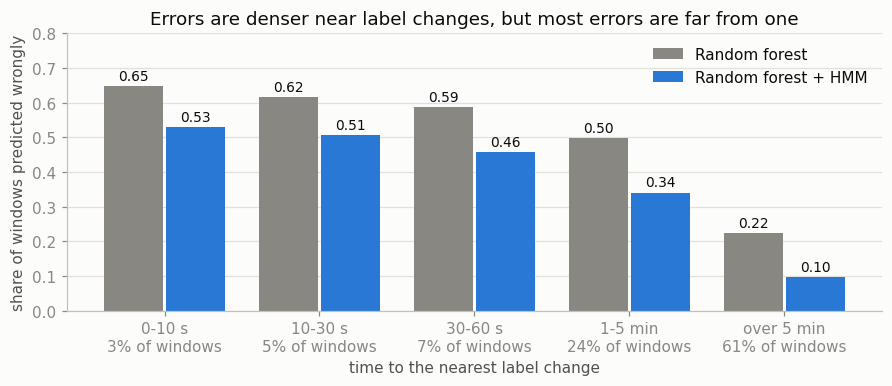

In [9]:
def plot_error_by_distance(table):
    fig, ax = plt.subplots(figsize=(8, 3.4), layout="constrained")
    x = np.arange(len(table))
    for offset, model, label, color in ((-0.2, "A", NAMES["A"], MUTED), (0.2, "B", NAMES["B"], BLUE)):
        bars = ax.bar(x + offset, table[f"{model} error rate"], width=0.38, color=color, label=label)
        ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=9)
    ax.set_xticks(x, [f"{name}\n{share:.0%} of windows" for name, share in table["share of windows"].items()])
    ax.set(xlabel="time to the nearest label change", ylabel="share of windows predicted wrongly", ylim=(0, 0.8),
           title="Errors are denser near label changes, but most errors are far from one")
    ax.grid(axis="x", visible=False)
    ax.legend()
    fig.savefig(OUT / "error_by_distance.png", dpi=150)


ERRORS = error_by_distance()
plot_error_by_distance(ERRORS)

*Table 1.* Scores of the random forest + HMM with the windows within 30 s of a change left out, then the bins of Figure 1 in numbers.

In [10]:
beyond_30s = [DISTANCE[rows] >= 3 for rows in CV_ROWS]
away = pd.DataFrame([metrics_from_cm(confusion_matrix(Y[rows][f], pred[f], labels=range(K)))
                     for rows, pred, f in zip(CV_ROWS, CV_PRED["B"], beyond_30s)])
print(pd.DataFrame({"all labelled windows": B_CV[list(SHOWN)].mean(),
                    "more than 30 s from a change": away[list(SHOWN)].mean()}).rename(index=SHOWN).round(3).to_string())
ERRORS.rename(columns={"A error rate": "random forest error rate", "B error rate": "random forest + HMM error rate",
                      "share of B's errors": "share of random forest + HMM errors"}).round(3)

          all labelled windows  more than 30 s from a change
macro-F1                 0.522                         0.533
κ                        0.708                         0.737


,random forest error rate,random forest + HMM error rate,share of windows,share of random forest + HMM errors
0-10 s,0.647,0.530,0.027,0.068
10-30 s,0.617,0.507,0.053,0.127
30-60 s,0.587,0.458,0.066,0.141
1-5 min,0.498,0.341,0.244,0.390
over 5 min,0.223,0.096,0.609,0.274


Errors are denser near label changes. The random forest + HMM is wrong on 53% of windows within 10 s of a change, and on 10% of windows more than 5 min from one. Few windows are near a change, though. Those within 30 s are 8% of windows and 19% of the errors. Leaving them out raises κ from 0.708 to 0.737, so uncertain label timing explains at most 0.03 κ.

Two thirds of the errors are more than a minute from any change. The 1-5 min bin holds the largest share, 39%. That suggests bouts of a few minutes misread as a whole, though distance to a change cannot show it directly. A model that sees more than 10 s at a time could fix those. The error rate 1-5 min from a change is tracked for every model below.

Why so few windows sit near a change: how the labelled runs end in P001-P100.

In [11]:
adjacent = (SEQ[1:] == SEQ[:-1]) & IS_DEV[1:]
both = adjacent & LABELLED[1:] & LABELLED[:-1]
change = adjacent & (Y[1:] != Y[:-1])
trans = fit_hmm(Y[IS_DEV], SEQ[IS_DEV], K)["trans"]
print(f"adjacent pairs of labelled windows: {both.sum():,}; of those, two different activities: {(both & change).sum()}")
print(f"label changes: {change.sum():,}; into or out of 'unlabelled': {(change & ~both).sum():,}")
print(f"the HMM's transition matrix: {(trans[~np.eye(K, dtype=bool)] == 0).sum()} of {K * (K - 1)} off-diagonal entries are zero")

adjacent pairs of labelled windows: 609,580; of those, two different activities: 46
label changes: 16,948; into or out of 'unlabelled': 16,902
the HMM's transition matrix: 72 of 90 off-diagonal entries are zero


Annotators leave an unlabelled gap at almost every change of activity: only 46 of 609,580 adjacent pairs of labelled windows are two different activities. The HMM counts transitions between adjacent labelled windows only, so most of its transition matrix is zero. It comes out close to "never switch unless the forest insists". The matrix is fitted on training participants only, so this is no leak.

## 2. A pretrained encoder

The encoder is `harnet10` from `ssl-wearables` (Yuan et al., 2024), an 18-layer 1D ResNet with about 11M parameters. It was pretrained without labels on 700,000 person-days of UK Biobank wrist data (Doherty et al., 2017), and no CAPTURE-24 data was used to pretrain it. It takes 10 s at 30 Hz. So each window is resized from 1,000 to 300 samples by linear interpolation, as its authors do, and stored once.

The encoder's authors report CAPTURE-24 results for 4 intensity classes only. Their later tool ActiNet (Acquah et al., 2025) uses the same encoder with a trained final layer, followed by an HMM and a sleep correction. The first version of its paper keeps the encoder frozen, and the current version fine-tunes all layers. ActiNet uses 30 s windows and 4 intensity classes. It is evaluated with 5-fold cross-validation over all 151 participants, so its numbers are not comparable to the 10-class results here. To our knowledge, no 10-class result for this encoder on CAPTURE-24 has been published.

The fine-tuning settings were fixed before any score was seen, following the encoder's authors where they give them. All layers are trained with Adam in its AMSGrad variant, at learning rate 1e-4. Batches hold 1,000 windows, with no augmentation. A fifth of the training participants are held out for early stopping. Training stops when their loss has not improved for 5 epochs, and the best epoch is kept. Three seeds are run per fold. The fine-tuned encoder + HMM follows the recipe of ActiNet's current version, applied to 10 classes and 10 s windows without the sleep correction.

A network's softmax already includes how common each activity is. The HMM expects scores without that, as a balanced forest gives, so the softmax is divided by the training class frequencies first (Bourlard & Morgan, 1994).

Every window resampled to 30 Hz, stored once on disk and read as needed.

In [12]:
if not STORE.exists():
    deep.build_store(sorted(RAW.glob("P[0-9][0-9][0-9].csv.gz")), len(windows), STORE, STORE_START)
X30 = np.load(STORE, mmap_mode="r")  # (windows, 3, 300) float16, memory-mapped
assert (np.load(STORE_START) == START).all(), "the 30 Hz store does not line up with the feature cache"

The fine-tuning fit, run with three seeds on each fold.

In [13]:
def early_stopping_split(train):
    """A fifth of the training participants, held out for early stopping; the same for every kind of fit and seed."""
    return har.early_stopping_split(Y, GROUPS, train, SEED)


def fine_tuned(split, train, test, seed=SEED):
    def fit():
        fit_rows, val_rows = (rows[LABELLED[rows]] for rows in early_stopping_split(train))
        model = deep.fine_tune(X30, Y, fit_rows, val_rows, seed, **FINE_TUNING)
        return deep.encoder_proba(model, X30, test)
    return cached(fit, model="fine-tuned", variant="natural", split=split, seed=seed, settings=FINE_TUNING)


DEEP_CV = {seed: [fine_tuned(f"fold{i}", train, valid, seed) for i, (train, valid) in enumerate(FOLDS)] for seed in SEEDS}

The frozen encoder's output for every window, computed once and stored on disk.

In [14]:
if not deep.EMBEDDINGS.exists():
    deep.build_embeddings(X30, deep.EMBEDDINGS)
EMBEDDED = np.load(deep.EMBEDDINGS, mmap_mode="r")  # (windows, 1024) float16, memory-mapped

## 3. A model that sees minutes

Section 1 suggests most of the errors are bouts of a few minutes. This section asks whether context from minutes recovers the bouts that a single-window model misreads.

Every window goes once through the encoder as downloaded, never trained on CAPTURE-24 labels, which gives 1,024 numbers per window. A 2-layer bidirectional GRU reads them for consecutive windows and outputs an activity for each. It has 128 units per direction and dropout 0.5. It trains on chunks of 64 consecutive windows, about 10 min. A new chunk starts every 32 windows. Unlabelled windows are part of the input and carry no loss. At prediction it reads each whole recording. This is the frozen encoder + BiGRU, and it tests the kind of recurrent model that ActiNet's authors list as future work.

The control is the frozen encoder + HMM: the same network on single windows, followed by the HMM. It shares the frozen encoder, so the difference between the two is context. It is ActiNet's recipe, as in the first version of its paper, applied to the 10-class scheme with 10 s windows, without the sleep correction.

The settings are Adam with learning rate 1e-3 and 16,384 windows per batch. Early stopping uses the same participants as the fine-tuning, with a patience of 5 epochs. Training uses the natural class frequencies, three seeds per fold and the same five folds.

There are two candidates. One is the frozen encoder + BiGRU's top class. The other is its $\text{softmax} / \text{prior}$ through the HMM, the frozen encoder + BiGRU + HMM. The one with the higher cross-validation macro-F1, averaged over seeds, is scored on the held-out participants once, with seed 42. If the two are within 0.005, the higher κ decides.

This section, up to the held-out scores, was written before any score of the new model was seen.

The recurrent network's fit for the frozen encoder + BiGRU and the frozen encoder + HMM, three seeds each, on every fold.

In [15]:
LENGTHS = (1, CONTEXT_LENGTH)  # single windows, and the context model


def context_fit(inputs, length, split, train, test, seed=SEED):
    def fit():
        Z = EMBEDDED if inputs == "encoder" else scaled_features(train)
        model = deep.fit_context(Z, Y, SEQ, *early_stopping_split(train), length, seed, **CONTEXT)
        return deep.context_proba(model, Z, SEQ, test, length)
    return cached(fit, model="context", inputs=inputs, length=length, split=split, seed=seed, settings=CONTEXT)


def context_cv(inputs, length, seed):
    return [context_fit(inputs, length, f"fold{i}", train, valid, seed) for i, (train, valid) in enumerate(FOLDS)]


CONTEXT_CV = {(length, seed): context_cv("encoder", length, seed) for length in LENGTHS for seed in SEEDS}

Each model's per-fold scores averaged over seeds, the spread over seeds, and the error rate 1-5 min from a label change.

In [16]:
def summary(by_seed):
    per_seed = pd.DataFrame([{**cv_scores(preds)[list(SHOWN)].mean().rename(SHOWN), MID_ERROR: mid_error(preds)} for preds in by_seed])
    fold_mean = sum(cv_scores(preds)[list(SHOWN)] for preds in by_seed) / len(by_seed)
    spread = {f"{label}, spread over seeds": per_seed[label].std() for label in SHOWN.values()}
    return fold_mean, {**per_seed.mean(), **spread}


MODELS = {"B": [CV_PRED["B"]],
          "Deep + HMM": [hmm_cv(probas) for probas in DEEP_CV.values()],
          "Single windows + HMM": [hmm_cv(CONTEXT_CV[1, seed]) for seed in SEEDS],
          "Context": [top_class_cv(CONTEXT_CV[CONTEXT_LENGTH, seed]) for seed in SEEDS],
          "Context + HMM": [hmm_cv(CONTEXT_CV[CONTEXT_LENGTH, seed]) for seed in SEEDS]}
SUMMARY = {name: summary(by_seed) for name, by_seed in MODELS.items()}
CV = {name: fold_mean for name, (fold_mean, _) in SUMMARY.items()}

In [17]:
TIE = abs(CV["Context"]["macro_f1"].mean() - CV["Context + HMM"]["macro_f1"].mean()) < 0.005
CONTEXT_MODEL = max(("Context", "Context + HMM"), key=lambda name: CV[name]["kappa" if TIE else "macro_f1"].mean())
print("chosen for the held-out participants:", NAMES[CONTEXT_MODEL], "(by κ: within 0.005 macro-F1)" if TIE else "")

chosen for the held-out participants: Frozen encoder + BiGRU (by κ: within 0.005 macro-F1)


*Table 2.* Every model in cross-validation: scores, the error rate 1-5 min from a label change, and the change against the random forest + HMM (mean ± standard error over folds). The networks are means over three seeds.

In [18]:
CV_TABLE = pd.DataFrame({name: row for name, (_, row) in SUMMARY.items()}).T
CV_TABLE = CV_TABLE.join(pd.DataFrame({name: against_b(s) for name, s in CV.items() if name != "B"}).T)
SPREAD = CV_TABLE.filter(like="spread over seeds").columns
print(f"largest spread over seeds: {CV_TABLE[SPREAD].max().max():.3f}")
SHOWN_TABLE = CV_TABLE.drop(columns=SPREAD).rename(index=NAMES, columns=lambda c: c.replace("against B", "against random forest + HMM"))
SHOWN_TABLE.map(lambda v: round(v, 3) if isinstance(v, float) else v).fillna("")

largest spread over seeds: 0.011


,macro-F1,κ,error rate 1-5 min from a change,macro-F1 against random forest + HMM,κ against random forest + HMM
Random forest + HMM,0.522,0.708,0.341,,
Fine-tuned encoder + HMM,0.578,0.741,0.286,+0.056 ± 0.018,+0.033 ± 0.003
Frozen encoder + HMM,0.603,0.776,0.250,+0.081 ± 0.029,+0.068 ± 0.014
Frozen encoder + BiGRU,0.580,0.814,0.209,+0.058 ± 0.028,+0.105 ± 0.014
Frozen encoder + BiGRU + HMM,0.584,0.766,0.284,+0.062 ± 0.024,+0.058 ± 0.013


- The frozen encoder + BiGRU has the lowest error rate 1-5 min from a label change, 0.21, against 0.34 for the random forest + HMM. The frozen encoder + HMM, which differs only in context, has 0.25. The frozen encoder + BiGRU's κ is 0.814, which is 0.105 above the random forest + HMM. Each network's spread over seeds is at most 0.011.
- Macro-F1 moves less. The frozen encoder + BiGRU is 0.058 above the random forest + HMM, and level with the fine-tuned encoder + HMM. Their macro-F1 scores are 0.580 and 0.578.
- The HMM no longer helps. It lowers the frozen encoder + BiGRU's κ from 0.814 to 0.766 and leaves macro-F1 about the same. The network already removes the flicker, so the HMM only holds each activity too long. The frozen encoder + BiGRU without the HMM goes to the held-out participants.
- The frozen encoder is at least as good as the fine-tuned one here. The frozen encoder + HMM scores macro-F1 0.603 and κ 0.776. The fine-tuned encoder + HMM scores 0.578 and 0.741. The two also have different heads, and one fine-tuning recipe was tried.

## 4. Held-out participants

The random forest + HMM, the fine-tuned encoder + HMM and the chosen context model are fitted on P001-P100 with seed 42 and scored once on P101-P151. The random forest + HMM must reproduce part 1's held-out scores. Intervals are 95% percentile bootstraps over participants, with 2,000 draws (Field & Welsh, 2007). Differences between models are paired: both models' scores come from the same draws of participants.

The frozen encoder + HMM, the ActiNet-style model, is also scored on the held-out participants as a baseline. Its configuration is the one used in section 3's cross-validation: seed 42, the network on single windows of the frozen encoder's output, its softmax divided by the training class prior, then the random forest + HMM's HMM. It is fitted on P001-P100 with the same early-stopping split. Scoring a baseline selects nothing, and the reported model does not change.

In [19]:
DEV, TEST = np.flatnonzero(IS_DEV), np.flatnonzero(~IS_DEV)
SCORED = TEST[LABELLED[TEST]]
DEEP_TEST = fine_tuned("holdout", DEV, TEST)
CONTEXT_TEST = context_fit("encoder", CONTEXT_LENGTH, "holdout", DEV, TEST)
SINGLE_TEST = context_fit("encoder", 1, "holdout", DEV, TEST)
HOLDOUT_PRED = {"B": hmm_predict(forest_proba(DEV, TEST), DEV, TEST),
                "Deep + HMM": hmm_predict(DEEP_TEST / class_prior(DEV), DEV, TEST),
                "Single windows + HMM": hmm_predict(SINGLE_TEST / class_prior(DEV), DEV, TEST),
                CONTEXT_MODEL: (hmm_predict(CONTEXT_TEST / class_prior(DEV), DEV, TEST) if CONTEXT_MODEL == "Context + HMM"
                                else top_class(CONTEXT_TEST, TEST))}

Held-out scores with participant-bootstrap intervals, and paired differences on the same bootstrap draws.

In [20]:
def holdout_cms(pred):
    return har.participant_cms(Y[SCORED], pred, GROUPS[SCORED], K)


def score_holdout(pred):
    cms = holdout_cms(pred)
    point, draws = metrics_from_cm(cms.sum(axis=0)), har.bootstrap_metrics(cms, N_BOOT, SEED)
    return {**{m: interval(point[m], draws[m]) for m in SHOWN}, "per_class_f1": point["per_class_f1"]}


def paired_gain(pred, baseline):
    return har.paired_gain(holdout_cms(pred), holdout_cms(baseline), SHOWN, N_BOOT, SEED)


SCORES = {model: score_holdout(pred) for model, pred in HOLDOUT_PRED.items()}
assert np.allclose([SCORES["B"][m]["value"] for m in SHOWN], [PART1["tasks"]["10-class"]["B"]["holdout"][m]["value"] for m in SHOWN])
PAIRS = (("Deep + HMM", "B"), (CONTEXT_MODEL, "B"), (CONTEXT_MODEL, "Deep + HMM"), (CONTEXT_MODEL, "Single windows + HMM"))
GAINS = {f"{model} minus {base}": paired_gain(HOLDOUT_PRED[model], HOLDOUT_PRED[base]) for model, base in PAIRS}

*Table 3.* Held-out scores [95% interval] and paired differences.

In [21]:
cell = lambda s, sign="": f"{s['value']:{sign}.3f} [{s['ci'][0]:{sign}.3f}, {s['ci'][1]:{sign}.3f}]"
pd.DataFrame({**{NAMES[model]: {label: cell(s[m]) for m, label in SHOWN.items()} for model, s in SCORES.items()},
              **{f"{NAMES[model]} minus {NAMES[base]}": {label: cell(gain[m], "+") for m, label in SHOWN.items()}
                 for (model, base), gain in zip(PAIRS, GAINS.values())}}).T

,macro-F1,κ
Random forest + HMM,"0.566 [0.524, 0.595]","0.690 [0.653, 0.725]"
Fine-tuned encoder + HMM,"0.619 [0.557, 0.659]","0.742 [0.702, 0.778]"
Frozen encoder + HMM,"0.638 [0.571, 0.681]","0.750 [0.717, 0.783]"
Frozen encoder + BiGRU,"0.642 [0.577, 0.677]","0.790 [0.758, 0.819]"
Fine-tuned encoder + HMM minus Random forest + HMM,"+0.053 [+0.013, +0.085]","+0.052 [+0.029, +0.074]"
Frozen encoder + BiGRU minus Random forest + HMM,"+0.076 [+0.021, +0.111]","+0.100 [+0.076, +0.124]"
Frozen encoder + BiGRU minus Fine-tuned encoder + HMM,"+0.022 [-0.025, +0.057]","+0.048 [+0.026, +0.071]"
Frozen encoder + BiGRU minus Frozen encoder + HMM,"+0.004 [-0.025, +0.026]","+0.040 [+0.023, +0.057]"


Paired intervals pool participants. The cell below counts, for each comparison, the held-out participants on whom the frozen encoder + BiGRU has the higher κ.

In [22]:
def participant_kappa(pred):
    return np.array([metrics_from_cm(cm)["kappa"] for cm in holdout_cms(pred)])


KAPPA_BY_PARTICIPANT = {model: participant_kappa(pred) for model, pred in HOLDOUT_PRED.items()}
AHEAD = {base: int((KAPPA_BY_PARTICIPANT[CONTEXT_MODEL] > KAPPA_BY_PARTICIPANT[base]).sum())
         for base in HOLDOUT_PRED if base != CONTEXT_MODEL}
for base, n in AHEAD.items():
    print(f"{NAMES[CONTEXT_MODEL]} has the higher κ than {NAMES[base]} for {n} of {len(KAPPA_BY_PARTICIPANT[base])} held-out participants")

Frozen encoder + BiGRU has the higher κ than Random forest + HMM for 46 of 51 held-out participants
Frozen encoder + BiGRU has the higher κ than Fine-tuned encoder + HMM for 39 of 51 held-out participants
Frozen encoder + BiGRU has the higher κ than Frozen encoder + HMM for 42 of 51 held-out participants


*Figure 2.* Held-out macro-F1 and κ with 95% intervals. Diamonds are the cross-validation means, and grey bars are the paper's published numbers.

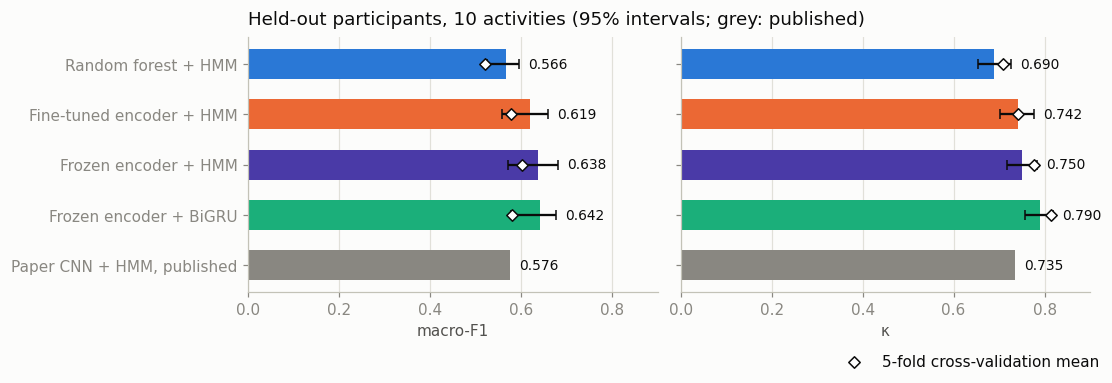

In [23]:
# name -> (held-out scores, cross-validation means, colour)
SHOWN_MODELS = {NAMES[name]: (SCORES[name], CV[name][list(SHOWN)].mean(), color)
                for name, color in (("B", BLUE), ("Deep + HMM", ORANGE), ("Single windows + HMM", PURPLE), (CONTEXT_MODEL, GREEN))}
title = "Held-out participants, 10 activities (95% intervals; grey: published)"
har.plot_holdout(SHOWN_MODELS, PUBLISHED, title).savefig(OUT / "results_new_model.png", dpi=150)
# The paper's band figure: part 1's excerpt of P101, with the frozen encoder + BiGRU in place of the random forest.
bands = {"camera labels": Y[SCORED], SHORT["B"]: HOLDOUT_PRED["B"], SHORT[CONTEXT_MODEL]: HOLDOUT_PRED[CONTEXT_MODEL]}
har.save_for_paper(har.plot_bands(START[SCORED], GROUPS[SCORED], bands), PAPER_FIGURES / "bands.png")

*Table 4.* F1 per activity, in cross-validation (folds pooled) and held out. For the networks, each seed's predictions are pooled over folds, and the per-activity F1 is averaged over the three seeds.

In [24]:
def seed_mean_f1(name):
    return np.mean([pooled_f1(preds) for preds in MODELS[name]], axis=0)


pd.DataFrame({**{f"{NAMES[name]} CV": seed_mean_f1(name) for name in ("B", "Single windows + HMM", CONTEXT_MODEL)},
              **{f"{NAMES[name]} held out": SCORES[name]["per_class_f1"] for name in ("B", "Single windows + HMM", CONTEXT_MODEL)}},
             index=CODES).loc[CLASSES].round(3)

,Random forest + HMM CV,Frozen encoder + HMM CV,Frozen encoder + BiGRU CV,Random forest + HMM held out,Frozen encoder + HMM held out,Frozen encoder + BiGRU held out
sleep,0.970,0.974,0.989,0.980,0.982,0.993
sitting,0.861,0.903,0.934,0.873,0.896,0.928
standing,0.277,0.371,0.318,0.300,0.357,0.348
household-chores,0.596,0.653,0.700,0.531,0.620,0.631
manual-work,0.146,0.241,0.060,0.072,0.341,0.212
walking,0.422,0.498,0.539,0.426,0.469,0.546
mixed-activity,0.184,0.338,0.301,0.136,0.254,0.340
vehicle,0.792,0.900,0.882,0.733,0.956,0.966
sports,0.251,0.526,0.334,0.802,0.648,0.604
bicycling,0.820,0.904,0.879,0.810,0.857,0.851


Against the random forest + HMM, paired, the frozen encoder + BiGRU gains 0.100 κ (0.076 to 0.124). Its macro-F1 gain is 0.076 (0.021 to 0.111).

On held-out participants, the frozen encoder + BiGRU is above the ActiNet-style frozen encoder + HMM by +0.040 κ [0.023, 0.057]. Their macro-F1 difference is +0.004 [-0.025, 0.026]. Against the fine-tuned encoder + HMM, the frozen encoder + BiGRU gains 0.048 κ (0.026 to 0.071). Their macro-F1 difference is +0.022, with an interval from -0.025 to 0.057. The fine-tuned encoder + HMM is itself above the random forest + HMM, by 0.052 κ (0.029 to 0.074).

The paper's published κ for its CNN + HMM, 0.735, is below the frozen encoder + BiGRU's interval. Its macro-F1, 0.576, is just below that interval's lower edge of 0.577.

By activity, the frozen encoder + BiGRU is above the random forest + HMM on every activity in cross-validation except manual work, which it almost never predicts (F1 0.060 against 0.146). That is one reason κ rises more than macro-F1. Held out, it is above on every activity except sports, which only 8 participants did.

## 5. Where the gain comes from

The comparisons above mix two things: the model, and the rule that turns its output into a class. The frozen encoder + BiGRU keeps the class frequencies in its output, and the HMM models divide them out. Keeping them favours common activities and κ. Removing them favours rare activities and macro-F1. So each model is scored here at five settings of one dial, $\text{output} / \text{prior}^{\alpha}$ (Saerens et al., 2002). The dial runs from $\alpha = 0$, class frequencies kept, to $\alpha = 1$, fully removed. Scores are on the cross-validation folds, averaged over three seeds; the random forest + HMM has one fit.

To separate the encoder from the context, the same two networks are also trained on the 39 hand-made features, standardised with each fold's training participants. These are the features + HMM (network) and the features + BiGRU. They were added after the held-out scores above, so they are scored in cross-validation only. Their settings were copied unchanged from the encoder networks.

The two networks on the hand-made features, three seeds each on every fold.

In [25]:
def scaled_features(train):
    mean, sd = X[train].mean(axis=0), X[train].std(axis=0)
    return ((X - mean) / sd).astype(np.float32)


FEATURE_CV = {(length, seed): context_cv("features", length, seed) for length in LENGTHS for seed in SEEDS}

Every model's cross-validation scores as its output is divided by the class prior to the power $\alpha$.

In [26]:
ALPHAS = [0, 0.25, 0.5, 0.75, 1]
# name -> (one list of fold outputs per seed, HMM, forest, colour, line style, alpha used in sections 3 and 4)
CURVES = {"B": ([FOREST_CV], True, True, BLUE, "-", 1),
          "Single windows + HMM": ([CONTEXT_CV[1, seed] for seed in SEEDS], True, False, PURPLE, "-", 1),
          "Context": ([CONTEXT_CV[CONTEXT_LENGTH, seed] for seed in SEEDS], False, False, GREEN, "-", 0),
          "Hand-made features, single windows + HMM": ([FEATURE_CV[1, seed] for seed in SEEDS], True, False, PURPLE, ":", None),
          "Hand-made features, context": ([FEATURE_CV[CONTEXT_LENGTH, seed] for seed in SEEDS], False, False, GREEN, ":", None)}


def prior_curve(by_seed, hmm, forest):
    """Cross-validation scores, mean over seeds, with the class frequencies removed to the power alpha: output ÷ prior^alpha.
    A balanced forest's output has them removed already, so there they are put back: output × prior^(1 - alpha)."""
    curve = {}
    for alpha in ALPHAS:
        per_seed = []
        for probas in by_seed:
            liks = [proba * class_prior(train) ** (1 - alpha if forest else -alpha) for proba, (train, _) in zip(probas, FOLDS)]
            preds = hmm_cv(liks, divide=False) if hmm else top_class_cv(liks)
            per_seed.append(cv_scores(preds)[list(SHOWN)].mean().rename(SHOWN))
        curve[alpha] = pd.DataFrame(per_seed).mean()
    return pd.DataFrame(curve).T


RULE = {name: prior_curve(by_seed, hmm, forest) for name, (by_seed, hmm, forest, *_) in CURVES.items()}

*Figure 3.* Macro-F1 against κ for each model as the decision rule moves from class frequencies kept ($\alpha = 0$) to removed ($\alpha = 1$). Rings mark the rule each model used in sections 3 and 4. Dotted lines are the same networks on the hand-made features; they have no ring because they were never scored held out.

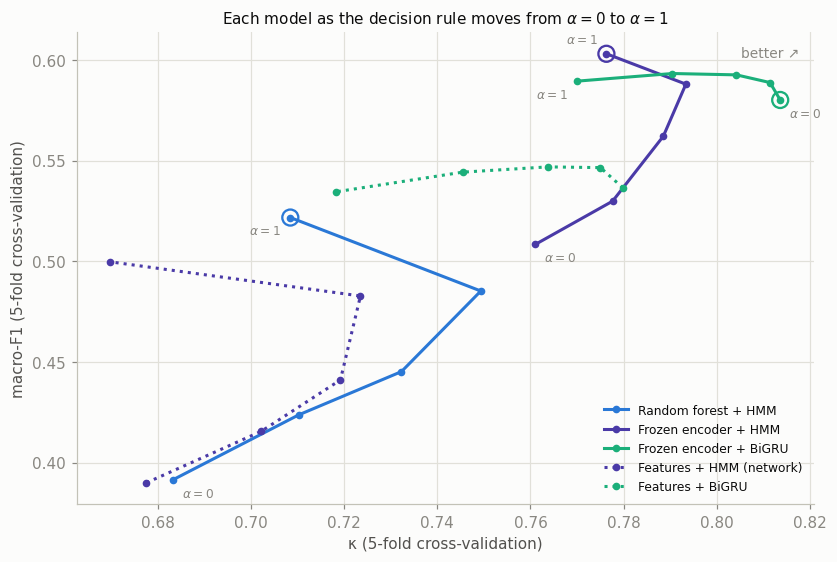

In [27]:
def plot_rule_curves(names):
    fig, ax = plt.subplots(figsize=(7.5, 5), layout="constrained")
    for name, (*_, color, style, used) in CURVES.items():
        curve = RULE[name]
        ax.plot(curve["κ"], curve["macro-F1"], color=color, linestyle=style, linewidth=2, marker="o", markersize=4, label=names[name])
        if used is not None:
            ax.scatter(*curve.loc[used, ["κ", "macro-F1"]], s=110, facecolor="none", edgecolor=color, linewidth=1.5, zorder=3)
        if style == "-":
            for alpha, dx in ((0, 6), (1, -6)):
                dy = 7 if (name, alpha) == ("Single windows + HMM", 1) else -11  # keeps the two α = 1 labels near the top apart
                ax.annotate(rf"$\alpha={alpha}$", curve.loc[alpha, ["κ", "macro-F1"]], xytext=(dx, dy),
                            textcoords="offset points", ha="left" if dx > 0 else "right", fontsize=8, color=MUTED)
    ax.set(xlabel="κ (5-fold cross-validation)", ylabel="macro-F1 (5-fold cross-validation)")
    ax.annotate("better ↗", (0.98, 0.97), xycoords="axes fraction", ha="right", va="top", fontsize=9, color=MUTED)
    ax.set_title(r"Each model as the decision rule moves from $\alpha=0$ to $\alpha=1$", fontsize=10)
    ax.legend(loc="lower right", fontsize=8)
    return fig


plot_rule_curves(NAMES).savefig(OUT / "decision_rule.png", dpi=150)
har.save_for_paper(plot_rule_curves(SHORT), PAPER_FIGURES / "decision_rule.png")

*Table 5.* Each model at its best rule for κ and at its best rule for macro-F1.

In [28]:
BEST = pd.DataFrame({name: {"best κ": curve["κ"].max(), "macro-F1 there": curve.loc[curve["κ"].idxmax(), "macro-F1"],
                            "best macro-F1": curve["macro-F1"].max(), "κ there": curve.loc[curve["macro-F1"].idxmax(), "κ"]}
                     for name, curve in RULE.items()}).T
BEST.rename(index=NAMES).round(3)

,best κ,macro-F1 there,best macro-F1,κ there
Random forest + HMM,0.749,0.485,0.522,0.708
Frozen encoder + HMM,0.793,0.588,0.603,0.776
Frozen encoder + BiGRU,0.814,0.580,0.593,0.790
Features + HMM (network),0.724,0.483,0.500,0.670
Features + BiGRU,0.780,0.536,0.547,0.764


- At each model's best rule, the frozen encoder + BiGRU's κ gain over the random forest + HMM is 0.064, down from 0.105 at the rules used above. About 40% of the cross-validation gap is the decision rule, and the rest is the model.
- The encoder adds 0.070 κ without context and 0.034 with it. Context adds 0.056 on the hand-made features and 0.020 on the encoder. Each helps less when the other is present.
- No model gets much past macro-F1 0.60 (Table 5).

Every score goes to `outputs/results_new_model.json`.

In [29]:
def save_results():
    as_dict = lambda frame: json.loads(frame.to_json(orient="index"))
    results = {"config": {"seed": SEED, "seeds": SEEDS, "n_folds": N_FOLDS, "n_boot": N_BOOT, "shared": SHARED,
                          "fine_tuning": FINE_TUNING, "context": CONTEXT, "chosen_context": CONTEXT_MODEL},
               "error_by_distance_cv": as_dict(ERRORS),
               "cv": as_dict(CV_TABLE),
               "decision_rule_cv": {name: as_dict(curve) for name, curve in RULE.items()},
               "decision_rule_best_cv": as_dict(BEST),
               "holdout": {model: {m: s[m] for m in SHOWN} for model, s in SCORES.items()},
               "holdout_paired_gains": GAINS,
               "holdout_participants_ahead_on_kappa": AHEAD,
               "holdout_per_class_f1": {model: dict(zip(CODES, s["per_class_f1"])) for model, s in SCORES.items()}}
    (OUT / "results_new_model.json").write_text(json.dumps(results, indent=2))


save_results()
print(f"run time: {(perf_counter() - T0) / 60:.1f} min")

run time: 6.6 min


## 6. Limitations and next steps

- That the frozen encoder + BiGRU improves macro-F1 is not shown. It is level with the fine-tuned encoder + HMM in cross-validation, and their held-out difference has an interval that includes zero.
- That any model here beats the paper's CNN + HMM is not shown. Its numbers come from the paper and were never rerun, so nothing is paired with it. It was trained from scratch, while every model here but the random forest + HMM starts from a pretrained encoder.
- Selection on the same folds. The fine-tuned model's HMM variant, the context candidate and the decision rules were chosen on the cross-validation folds whose scores are reported, which favours them there. Those folds share most of their training participants, so their spreads understate the uncertainty, and a cross-validation gap of 0.02 is only suggestive.
- Held-out looks. The frozen encoder + BiGRU was scored on the held-out participants once, with one seed. Over the project they have been scored six times: the random forest + HMM twice, the rerun of the paper's pipeline, the fine-tuned encoder + HMM, the frozen encoder + BiGRU and the frozen encoder + HMM. Held-out macro-F1 leans on activities few participants did, such as sports, which 8 of them did. The encoder's authors are the dataset's authors and evaluated it on CAPTURE-24 for 4 classes. So the encoder was never trained on these labels, but its design was not chosen independently of this benchmark.
- One population. CAPTURE-24 and the encoder's UK Biobank pretraining data are both UK adults wearing the same wrist device.
- Offline only. The frozen encoder + BiGRU reads whole recordings forwards and backwards.

Next steps:

- Rare activities. For the frozen encoder + BiGRU, manual work and mixed activity stay near or below F1 0.3 in cross-validation, and their labels overlap with household chores and walking. A class-weighted loss, or merging labels that annotators cannot separate, would test whether the limit is the model or the labels.
- Continuously labelled data. Labelled windows almost never sit on a change of activity, so every score describes the inside of bouts. The same label gaps make the HMM's transition matrix close to "never switch" (section 1). Data labelled through activity changes would show how much of each score depends on that.

## References

- Acquah, A., Chan, S., & Doherty, A. (2025). ActiNet: An open-source tool for activity intensity classification of wrist-worn accelerometry using self-supervised deep learning. *arXiv:2510.01712* (v1, October 2025; v2, April 2026). https://arxiv.org/abs/2510.01712
- Bourlard, H. A., & Morgan, N. (1994). *Connectionist speech recognition: A hybrid approach*. Kluwer Academic. https://doi.org/10.1007/978-1-4615-3210-1
- Chan, S., Yuan, H., Tong, C., Acquah, A., Schonfeldt, A., Gershuny, J., & Doherty, A. (2024). CAPTURE-24: A large dataset of wrist-worn activity tracker data collected in the wild for human activity recognition. *Scientific Data*, 11, 1135. https://doi.org/10.1038/s41597-024-03960-3
- Doherty, A., Jackson, D., Hammerla, N., Plötz, T., Olivier, P., Granat, M. H., White, T., van Hees, V. T., Trenell, M. I., Owen, C. G., Preece, S. J., Gillions, R., Sheard, S., Peakman, T., Brage, S., & Wareham, N. J. (2017). Large scale population assessment of physical activity using wrist worn accelerometers: The UK Biobank study. *PLoS ONE*, 12(2), e0169649. https://doi.org/10.1371/journal.pone.0169649
- Field, C. A., & Welsh, A. H. (2007). Bootstrapping clustered data. *Journal of the Royal Statistical Society: Series B*, 69(3), 369-390. https://doi.org/10.1111/j.1467-9868.2007.00593.x
- OxWearables. *ssl-wearables*: self-supervised pretrained models for wrist accelerometry. https://github.com/OxWearables/ssl-wearables (pinned to commit 150550e, University of Oxford Academic Use Licence)
- Rabiner, L. R. (1989). A tutorial on hidden Markov models and selected applications in speech recognition. *Proceedings of the IEEE*, 77(2), 257-286. https://doi.org/10.1109/5.18626
- Saerens, M., Latinne, P., & Decaestecker, C. (2002). Adjusting the outputs of a classifier to new a priori probabilities: A simple procedure. *Neural Computation*, 14(1), 21-41. https://doi.org/10.1162/089976602753284446
- Yuan, H., Chan, S., Creagh, A. P., Tong, C., Acquah, A., Clifton, D. A., & Doherty, A. (2024). Self-supervised learning for human activity recognition using 700,000 person-days of wearable data. *npj Digital Medicine*, 7, 91. https://doi.org/10.1038/s41746-024-01062-3